# Fase 3 — U-Net desde cero (Entregable 1)

**Requisito del enunciado:** *implementación personalizada de U-Net en PyTorch, sin copiar código de bibliotecas de segmentación, con al menos VV y VH como entrada.* → `src/modelo_unet.py` usa solo `torch.nn` básico.

## Teoría: ¿por qué una U-Net?
Segmentar = clasificar **cada píxel**. Hace falta responder dos preguntas a la vez:
- **¿Qué hay?** → requiere *contexto* amplio (¿esa mancha oscura es un río o una sombra de cerro?).
- **¿Dónde exactamente?** → requiere *resolución* fina (bordes del agua, canales de 2–3 píxeles).

Una CNN clasificadora (como las de clase: LeNet, VGG, ResNet) gana contexto **reduciendo resolución** y pierde el *dónde*. La U-Net (Ronneberger et al., 2015) resuelve eso con tres piezas:

1. **Codificador** (bajada): convoluciones + *max pooling*. Cada nivel reduce la resolución a la mitad y duplica los canales → más contexto, menos detalle.
2. **Decodificador** (subida): *convoluciones transpuestas* que duplican la resolución → reconstruye el mapa a tamaño completo.
3. **Conexiones de salto** (*skip connections*): concatenan el mapa del codificador del **mismo nivel** al decodificador. Le devuelven el detalle espacial que el *pooling* había descartado. Sin ellas, los bordes salen borrosos → por eso son candidatas para la **ablación (b)**.

La salida es **1 canal de logits** por píxel; aplicando sigmoide se obtiene P(agua). Umbral 0.5 ⇔ logit > 0.

**Campo receptivo:** cuántos píxeles de la entrada "ve" la red para decidir un píxel. Con 10 m/píxel, se traduce a kilómetros de contexto: clave para distinguir un río (alargado, continuo) de un charco o una sombra.

## 0. Preparación

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio

Mounted at /content/drive


## 1. Módulo nuevo: `src/modelo_unet.py`

In [3]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/modelo_unet.py
"""
modelo_unet.py
U-Net implementada desde cero (Ronneberger et al., 2015), adaptada a SAR de 2 bandas.

Arquitectura (profundidad=4, canales_base=c):
  Entrada (2, H, W)
  ├─ Codificador  : DobleConv(2→c) → [MaxPool + DobleConv] x4  (c→2c→4c→8c→16c)   "qué hay"
  ├─ Decodificador: [ConvTranspuesta ×2 + concatenar salto + DobleConv] x4         "dónde está"
  └─ Cabeza 1x1   : c → 1 canal = logit de "agua" por píxel

Diferencias con el paper original (documentarlas en el informe):
  - padding=1 ("same"): la salida tiene el mismo tamaño que la entrada (el original recortaba).
  - BatchNorm tras cada convolución (no existía en 2015; estabiliza y acelera el entrenamiento).
  - 1 canal de salida con sigmoide (problema binario) en vez de 2 con softmax.
  - Parámetros configurables para la ablación: profundidad, canales_base y usar_saltos.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class DobleConv(nn.Module):
    """(Conv 3x3 → BatchNorm → ReLU) x 2. Bloque básico de la U-Net."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        capas = [
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
            nn.Conv2d(canales_salida, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
        ]
        if abandono > 0:
            capas.append(nn.Dropout2d(abandono))
        self.bloque = nn.Sequential(*capas)

    def forward(self, x):
        return self.bloque(x)


class Bajada(nn.Module):
    """MaxPool 2x2 (reduce resolución a la mitad) + DobleConv (duplica canales)."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        self.agrupar = nn.MaxPool2d(2)
        self.conv = DobleConv(canales_entrada, canales_salida, abandono)

    def forward(self, x):
        return self.conv(self.agrupar(x))


class Subida(nn.Module):
    """ConvTranspuesta 2x2 (duplica resolución) + concatenar el salto del codificador + DobleConv."""

    def __init__(self, canales_entrada: int, canales_salida: int, usar_salto: bool = True):
        super().__init__()
        self.usar_salto = usar_salto
        self.subir = nn.ConvTranspose2d(canales_entrada, canales_entrada // 2, kernel_size=2, stride=2)
        canales_conv = canales_entrada // 2 + (canales_salida if usar_salto else 0)
        self.conv = DobleConv(canales_conv, canales_salida)

    def forward(self, x, salto):
        x = self.subir(x)
        # si H o W no eran divisibles entre 2^profundidad, ajustamos con padding al tamaño del salto
        dif_alto, dif_ancho = salto.shape[2] - x.shape[2], salto.shape[3] - x.shape[3]
        if dif_alto or dif_ancho:
            x = F.pad(x, [dif_ancho // 2, dif_ancho - dif_ancho // 2, dif_alto // 2, dif_alto - dif_alto // 2])
        if self.usar_salto:
            x = torch.cat([salto, x], dim=1)   # detalle espacial fino (salto) + contexto (x)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, canales_entrada: int = 2, canales_base: int = 32, profundidad: int = 4,
                 usar_saltos: bool = True, abandono: float = 0.0):
        super().__init__()
        self.configuracion = dict(canales_entrada=canales_entrada, canales_base=canales_base,
                                  profundidad=profundidad, usar_saltos=usar_saltos, abandono=abandono)
        canales = [canales_base * 2 ** i for i in range(profundidad + 1)]   # ej. 32, 64, 128, 256, 512

        self.entrada = DobleConv(canales_entrada, canales[0])
        # el abandono (dropout) solo en los niveles más profundos, donde hay más parámetros
        self.codificador = nn.ModuleList(
            Bajada(canales[i], canales[i + 1], abandono if i >= profundidad - 2 else 0.0)
            for i in range(profundidad)
        )
        self.decodificador = nn.ModuleList(
            Subida(canales[i + 1], canales[i], usar_saltos) for i in reversed(range(profundidad))
        )
        self.salida = nn.Conv2d(canales[0], 1, kernel_size=1)
        self._inicializar_pesos()

    def _inicializar_pesos(self):
        """He/Kaiming: pensada para ReLU, mantiene la varianza de las activaciones entre capas."""
        for modulo in self.modules():
            if isinstance(modulo, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(modulo.weight, mode="fan_out", nonlinearity="relu")
                if modulo.bias is not None:
                    nn.init.zeros_(modulo.bias)
            elif isinstance(modulo, nn.BatchNorm2d):
                nn.init.ones_(modulo.weight)
                nn.init.zeros_(modulo.bias)

    def forward(self, x, devolver_formas: bool = False):
        formas = [("entrada", tuple(x.shape))]
        x = self.entrada(x)
        saltos = [x]
        formas.append(("codificador nivel 0", tuple(x.shape)))
        for nivel, bajada in enumerate(self.codificador, start=1):
            x = bajada(x)
            saltos.append(x)
            formas.append((f"codificador nivel {nivel}" + (" (cuello)" if nivel == len(self.codificador) else ""),
                           tuple(x.shape)))
        saltos.pop()  # el cuello de botella no es salto de nadie
        for nivel, subida in zip(reversed(range(len(saltos))), self.decodificador):
            x = subida(x, saltos.pop())
            formas.append((f"decodificador nivel {nivel}", tuple(x.shape)))
        logits = self.salida(x)
        formas.append(("salida (logits)", tuple(logits.shape)))
        return (logits, formas) if devolver_formas else logits


def contar_parametros(modelo: nn.Module) -> int:
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def campo_receptivo(modelo: nn.Module, tamano: int = 512) -> int:
    """Campo receptivo EMPÍRICO: cuántos píxeles de la entrada influyen en el píxel central de la
    salida. Se mide con el gradiente: d(salida_centro)/d(entrada) es distinto de 0 solo dentro del campo.
    Indica cuánto 'contexto' mira la red para decidir si un píxel es agua."""
    estaba_entrenando = modelo.training
    modelo.eval()
    parametro = next(modelo.parameters())
    x = torch.randn(1, modelo.configuracion["canales_entrada"], tamano, tamano,
                    device=parametro.device, requires_grad=True)
    modelo(x)[0, 0, tamano // 2, tamano // 2].backward()
    influye = (x.grad.abs().sum(dim=(0, 1)) > 0)
    filas = torch.where(influye.any(dim=1))[0]
    modelo.train(estaba_entrenando)
    return int(filas.max() - filas.min() + 1)


Overwriting /content/drive/MyDrive/rnap_p2_inundaciones/src/modelo_unet.py


In [4]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F

from src.configuracion import *
from src.utilidades import fijar_semilla, obtener_dispositivo
from src.modelo_unet import UNet, contar_parametros, campo_receptivo

fijar_semilla(SEMILLA)
dispositivo = obtener_dispositivo()

OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU


## 2. Recorrido de un tensor por la red
**Qué observar:** en el codificador el alto/ancho se divide entre 2 y los canales se duplican; en el decodificador ocurre lo contrario; la salida tiene **el mismo tamaño que la entrada** y 1 canal.

In [5]:
modelo = UNet(canales_entrada=2, canales_base=32, profundidad=4).to(dispositivo)
with torch.no_grad():
    _, formas = modelo(torch.randn(1, 2, 256, 256, device=dispositivo), devolver_formas=True)
pd.DataFrame(formas, columns=['etapa', 'forma (lote, canales, alto, ancho)'])

,etapa,"forma (lote, canales, alto, ancho)"
0,entrada,"(1, 2, 256, 256)"
1,codificador nivel 0,"(1, 32, 256, 256)"
2,codificador nivel 1,"(1, 64, 128, 128)"
3,codificador nivel 2,"(1, 128, 64, 64)"
4,codificador nivel 3,"(1, 256, 32, 32)"
5,codificador nivel 4 (cuello),"(1, 512, 16, 16)"
6,decodificador nivel 3,"(1, 256, 32, 32)"
7,decodificador nivel 2,"(1, 128, 64, 64)"
8,decodificador nivel 1,"(1, 64, 128, 128)"
9,decodificador nivel 0,"(1, 32, 256, 256)"


## 3. Tamaño del modelo y campo receptivo
**Qué observar:**
- Los parámetros crecen ~×4 al duplicar `canales_base` y ~×4 por cada nivel extra (los niveles profundos tienen muchos canales).
- El campo receptivo solo depende de la profundidad.
- Con **252 chips** de entrenamiento, un modelo enorme sobreajustaría: buscamos el equilibrio.

In [6]:
filas = []
for profundidad in [3, 4, 5]:
    # el campo receptivo depende de la profundidad, no del ancho -> lo medimos con un modelo angosto
    campo = campo_receptivo(UNet(canales_base=8, profundidad=profundidad).to(dispositivo))
    for base in [16, 32, 64]:
        filas.append({'profundidad': profundidad, 'canales_base': base,
                      'parámetros (M)': round(contar_parametros(UNet(canales_base=base, profundidad=profundidad)) / 1e6, 2),
                      'campo receptivo (px)': campo, 'campo receptivo (km)': campo * 10 / 1000})
tabla_modelos = pd.DataFrame(filas)
tabla_modelos.to_csv(DIR_RESULTADOS / 'f3_tabla_modelos.csv', index=False)
tabla_modelos

,profundidad,canales_base,parámetros (M),campo receptivo (px),campo receptivo (km)
0,3,16,0.48,92,0.92
1,3,32,1.93,92,0.92
2,3,64,7.70,92,0.92
3,4,16,1.94,188,1.88
4,4,32,7.76,188,1.88
5,4,64,31.04,188,1.88
6,5,16,7.78,380,3.80
7,5,32,31.10,380,3.80
8,5,64,124.37,380,3.80


## 4. Memoria y velocidad en la T4 (precisión mixta)
**Precisión mixta (AMP):** las operaciones se hacen en `float16` donde es seguro → ~2× más rápido en la T4 (tiene *Tensor Cores*) y la mitad de memoria. El `GradScaler` evita que gradientes muy pequeños se vuelvan 0 en `float16`.

In [ ]:
def medir_paso(canales_base, profundidad, tamano_lote=8, tamano=256, repeticiones=10):
    modelo = UNet(canales_base=canales_base, profundidad=profundidad).to(dispositivo)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3)
    escalador = torch.amp.GradScaler('cuda')
    x = torch.randn(tamano_lote, 2, tamano, tamano, device=dispositivo)
    y = torch.randint(0, 2, (tamano_lote, 1, tamano, tamano), device=dispositivo).float()
    torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    for i in range(repeticiones + 2):
        if i == 2:  # las 2 primeras iteraciones son de calentamiento
            torch.cuda.synchronize(); inicio = time.time()
        with torch.autocast('cuda', dtype=torch.float16):   # precisión mixta (AMP)
            perdida = F.binary_cross_entropy_with_logits(modelo(x), y)
        optimizador.zero_grad(set_to_none=True)
        escalador.scale(perdida).backward()
        escalador.step(optimizador); escalador.update()
    torch.cuda.synchronize()
    resultado = {'canales_base': canales_base, 'profundidad': profundidad,
                 'ms por paso': round(1000 * (time.time() - inicio) / repeticiones, 1),
                 'memoria pico (GB)': round(torch.cuda.max_memory_allocated() / 1e9, 2)}
    del modelo, optimizador; torch.cuda.empty_cache()
    return resultado

pd.DataFrame([medir_paso(b, p) for b, p in [(16, 4), (32, 4), (64, 4), (32, 5)]])

## 5. Prueba de cordura: sobreajustar un solo lote
Esta prueba es una práctica estándar antes de entrenar en serio (Karpathy, *A Recipe for Training Neural Networks*): si el modelo **no puede memorizar 8 chips**, hay un error. **Esperado:** la pérdida baja de forma sostenida y el IoU sobre ese mismo lote supera ~0.9.

Primero se crean los cargadores de la fase 2 (tarda ~1 min por la carga en RAM).

In [7]:
from src.descarga import descargar_mano
from src.preprocesamiento import Normalizador
from src.cargadores import crear_cargadores

descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')
cargadores = crear_cargadores(normalizador, tamano_lote=8, tamano_recorte=256, num_workers=2, semilla=SEMILLA)

[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


Cargando chips en RAM:   0%|          | 0/252 [00:00<?, ?it/s]

train   : 252 chips ->  31 lotes


Cargando chips en RAM:   0%|          | 0/89 [00:00<?, ?it/s]

valid   :  89 chips ->  23 lotes


Cargando chips en RAM:   0%|          | 0/90 [00:00<?, ?it/s]

test    :  90 chips ->  23 lotes


Cargando chips en RAM:   0%|          | 0/15 [00:00<?, ?it/s]

bolivia :  15 chips ->   4 lotes


paso  10 | pérdida 0.1285 | IoU agua 0.812
paso  20 | pérdida 0.0685 | IoU agua 0.867
paso  30 | pérdida 0.0473 | IoU agua 0.903
paso  40 | pérdida 0.0365 | IoU agua 0.921
paso  50 | pérdida 0.0298 | IoU agua 0.935
paso  60 | pérdida 0.0268 | IoU agua 0.941
paso  70 | pérdida 0.0234 | IoU agua 0.947
paso  80 | pérdida 0.0202 | IoU agua 0.955
paso  90 | pérdida 0.0179 | IoU agua 0.960
paso 100 | pérdida 0.0149 | IoU agua 0.968


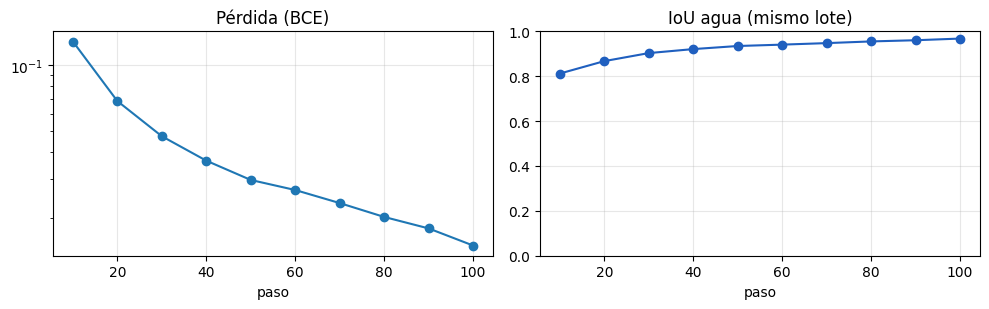

In [ ]:
# PRUEBA DE CORDURA: una red bien implementada debe poder MEMORIZAR un solo lote.
# Si no llega a IoU alto aquí, hay un bug (en el modelo, la máscara -1 o los datos) y no tiene sentido entrenar.
fijar_semilla(SEMILLA)
imagenes, etiquetas, ids = next(iter(cargadores['train']))
imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
validos = etiquetas != VALOR_SIN_DATO
objetivo = (etiquetas == 1).float()

modelo = UNet(canales_base=32, profundidad=4).to(dispositivo)
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
historial = []
for paso in range(1, 101): #Para GPU
#for paso in range(1, 301): #Para TPU
    logits = modelo(imagenes).squeeze(1)
    # BCE solo sobre píxeles válidos (los -1 no aportan gradiente)
    perdida = F.binary_cross_entropy_with_logits(logits[validos], objetivo[validos])
    optimizador.zero_grad(); perdida.backward(); optimizador.step()
    if paso % 10 == 0: #Para GPU
    #if paso % 25 == 0: #Para TPU
        with torch.no_grad():
            prediccion = (logits > 0)
            vp = (prediccion & (objetivo == 1) & validos).sum().item()
            fp = (prediccion & (objetivo == 0) & validos).sum().item()
            fn = (~prediccion & (objetivo == 1) & validos).sum().item()
        iou = vp / max(vp + fp + fn, 1)
        historial.append((paso, perdida.item(), iou))
        print(f"paso {paso:3d} | pérdida {perdida.item():.4f} | IoU agua {iou:.3f}")

pasos, perdidas, ious = zip(*historial)
figura, ejes = plt.subplots(1, 2, figsize=(10, 3.2))
ejes[0].plot(pasos, perdidas, marker='o'); ejes[0].set_title('Pérdida (BCE)'); ejes[0].set_yscale('log')
ejes[1].plot(pasos, ious, marker='o', color='#1f5fbf'); ejes[1].set_title('IoU agua (mismo lote)'); ejes[1].set_ylim(0, 1)
for eje in ejes: eje.set_xlabel('paso'); eje.grid(alpha=.3)
figura.tight_layout(); figura.savefig(DIR_FIGURAS / 'f3_prueba_sobreajuste.png', dpi=150)

## Decisión de arquitectura base (a confirmar con tus resultados)
**Propuesta:** `canales_base=32`, `profundidad=4` → ~7.8 M parámetros, campo receptivo ~188 px (~1.9 km).
- La U-Net original usa `canales_base=64` (~31 M): para 252 chips es ~4× más capacidad con alto riesgo de sobreajuste y el doble de tiempo por paso.
- 1.9 km de contexto alcanza para reconocer la forma de ríos y llanuras inundadas en un chip de 5.1 km.
- La **profundidad** y las **conexiones de salto** quedan como parámetros para la ablación (b).

## Para traer a la conversación
Las tablas de las secciones **3** y **4**, y la salida + figura de la sección **5**.